In [7]:
import numpy as np
import matplotlib.pyplot as plt 


from finite_differences import forward, backward, central, five_point, FD_NAMES, FD_METHODS

In [8]:
def exact_f(x):
    return np.sin(x) + np.cos(x/2.)

def exact_df(x):
    return np.cos(x) - np.sin(x/ 2.) /2. 

forward min error=  7.544233016076873e-10 at h=  9.426684551178853e-09
backward min error=  7.544233016076873e-10 at h=  9.426684551178853e-09
central min error=  7.718048422589163e-12 at h=  7.017038286703837e-06
5-point min error=  6.439293542825908e-15 at h=  0.00030702906297578496


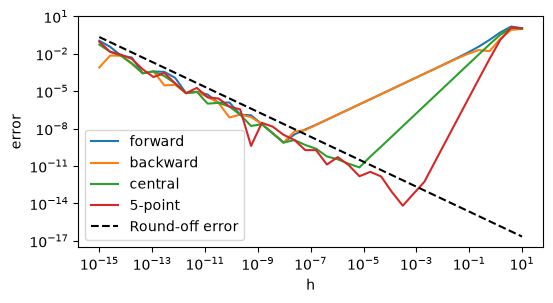

In [17]:
x0 = 0.0
hlist  = np.logspace(-15, 1, 40)

fig, ax = plt.subplots(figsize=(6,3))
for name, D in zip(FD_NAMES, FD_METHODS):
    df_approx = D(exact_f, x0, hlist)
    ax.loglog(hlist, np.abs( df_approx - exact_df(x0)) + 1e-16 , "-", label= name)
    print(name, "min error= ", np.min( np.abs( df_approx - exact_df(x0))) ,\
         "at h= ", hlist[np.argmin( np.abs( df_approx - exact_df(x0)))] )
ax.loglog(hlist, 2.2e-16 / hlist , "k--", label ="Round-off error")
ax.set_xlabel("h")
ax.set_ylabel("error") 

ax.legend()
plt.show()

In [18]:
def derivative_from_data(fvals, h):
    df = np.zeros_like(fvals)
    for i in range(1, len(fvals)-1):
        df[i] = (fvals[i+1] -fvals[i-1]) / (2.*h)
    # df[1:-1]= (df[2:] + df[:-2]) / (2*h)
    df[0] = (- 3*fvals[0] + 4*fvals[1] - fvals[2]) / (2.*h)
    df[-1] = (3*fvals[-1] - 4*fvals[-2] + fvals[-3]) / (2.*h)
    return df


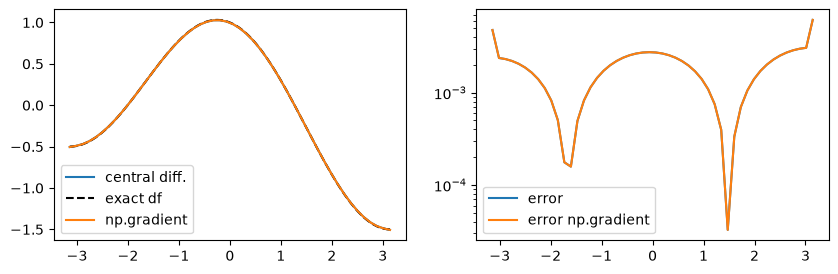

In [26]:
xs = np.linspace(- np.pi, np.pi, 50)
fs = exact_f(xs)
h = xs[1] - xs[0]
xdense = np.linspace(-np.pi, np.pi, 201)

fig, ax = plt.subplots(1,2, figsize=(10,3))
df_approx = derivative_from_data(fs, h)
ax[0].plot(xs, df_approx, label="central diff.")
ax[0].plot(xdense, exact_df(xdense), "k--", label="exact df")
ax[0].plot(xs, np.gradient(fs, h, edge_order=2), label="np.gradient")
ax[1].semilogy(xs, np.abs( df_approx - exact_df(xs)), label="error")
ax[1].semilogy(xs, np.abs( np.gradient(fs, h, edge_order=2) - exact_df(xs)), label="error np.gradient")
ax[0].legend()
ax[1].legend()
plt.show()